# Week 3: Supermarket Sales Data Analysis

**Project:** Supermarket Sales Data Analysis  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Objective
Analyze supermarket transaction data using the basic Data Science workflow:

**Raw Data → Exploration → Quality Check → Cleaning → Analysis → Visualization → Business Insights**

This notebook follows the Week 3 project checklist: load the dataset, explore it, check and clean data, calculate sales statistics, analyze categories, quantity, payment methods, customer types and daily sales, create visualizations, identify high/low sales and present business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/supermarket_sales.csv")
OUTPUT_PATH = Path("../outputs")
OUTPUT_PATH.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
display(df.head())

Dataset loaded successfully.


,Invoice ID,Date,Product,Category,Quantity,Unit Price,Customer Type,Payment,Total
0,1001,2023-01-11,Cap,Clothing,8,51.19,Normal,Credit Card,409.52
1,1002,2023-01-07,Milk,Beverages,7,3.12,Member,Cash,21.84
2,1003,2023-01-17,Soap,Household,10,23.87,Member,Digital Payment,238.70
3,1004,2023-01-21,Mouse,Electronics,10,53.81,Normal,Cash,538.10
4,1005,2023-01-09,Apples,Food,8,1.37,Member,Credit Card,10.96


## 1. Load and Explore the Dataset

In [2]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.select_dtypes(include=np.number).describe())

Shape: (1000, 9)

Columns:
['Invoice ID', 'Date', 'Product', 'Category', 'Quantity', 'Unit Price', 'Customer Type', 'Payment', 'Total']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     1000 non-null   int64  
 1   Date           1000 non-null   str    
 2   Product        1000 non-null   str    
 3   Category       1000 non-null   str    
 4   Quantity       1000 non-null   int64  
 5   Unit Price     1000 non-null   float64
 6   Customer Type  1000 non-null   str    
 7   Payment        1000 non-null   str    
 8   Total          1000 non-null   float64
dtypes: float64(2), int64(2), str(5)
memory usage: 70.4 KB

Statistical summary:


,Invoice ID,Quantity,Unit Price,Total
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,1500.500000,5.525000,14.800810,81.902280
std,288.819436,2.850877,18.235187,120.167821
min,1001.000000,1.000000,0.520000,0.760000
25%,1250.750000,3.000000,3.250000,13.432500
50%,1500.500000,5.500000,5.935000,31.780000
75%,1750.250000,8.000000,20.047500,86.625000
max,2000.000000,10.000000,79.980000,799.800000


## 2. Data Quality Check

In [3]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Duplicate records:", df.duplicated().sum())

print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["Unit Price"] <= 0).sum())
print("Invalid totals:", (df["Total"] <= 0).sum())

Missing values by column:


,Missing Values
Invoice ID,0
Date,0
Product,0
Category,0
Quantity,0
Unit Price,0
Customer Type,0
Payment,0
Total,0


Duplicate records: 0
Invalid quantities: 0
Invalid prices: 0
Invalid totals: 0


## 3. Data Cleaning

In [4]:
df = df.dropna().drop_duplicates().copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Unit Price"] = pd.to_numeric(df["Unit Price"], errors="coerce")
df["Total"] = pd.to_numeric(df["Total"], errors="coerce")

df = df.dropna(subset=["Date", "Quantity", "Unit Price", "Total"])
df = df[(df["Quantity"] > 0) & (df["Unit Price"] > 0) & (df["Total"] > 0)]

print("Shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicates:", df.duplicated().sum())

Shape after cleaning: (1000, 9)
Remaining missing values: 0
Remaining duplicates: 0


## 4. Sales Statistics

In [5]:
total_sales = df["Total"].sum()
average_sales = df["Total"].mean()
highest_sale = df["Total"].max()
lowest_sale = df["Total"].min()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Average Transaction Value: ${average_sales:,.2f}")
print(f"Highest Transaction: ${highest_sale:,.2f}")
print(f"Lowest Transaction: ${lowest_sale:,.2f}")

Total Sales: $81,902.28
Average Transaction Value: $81.90
Highest Transaction: $799.80
Lowest Transaction: $0.76


## 5. Sales by Category

,Total Sales
Category,
Electronics,34462.04
Clothing,24672.81
Household,10591.04
Food,8387.92
Beverages,3788.47


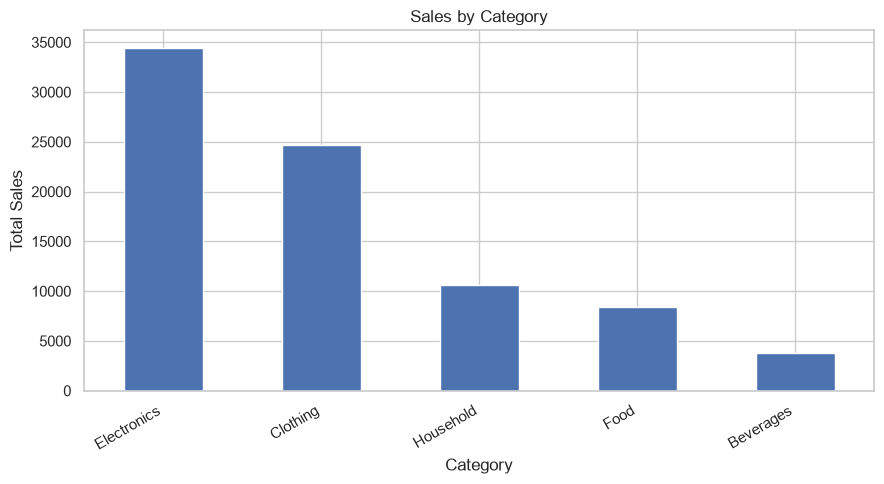

In [6]:
category_sales = df.groupby("Category")["Total"].sum().sort_values(ascending=False)
display(category_sales.to_frame("Total Sales"))

plt.figure(figsize=(9,5))
category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_PATH/"sales_by_category.png", dpi=160)
plt.show()

## 6. Product Quantity Analysis

,Quantity Sold
Category,
Food,1926
Beverages,1122
Household,853
Electronics,842
Clothing,782


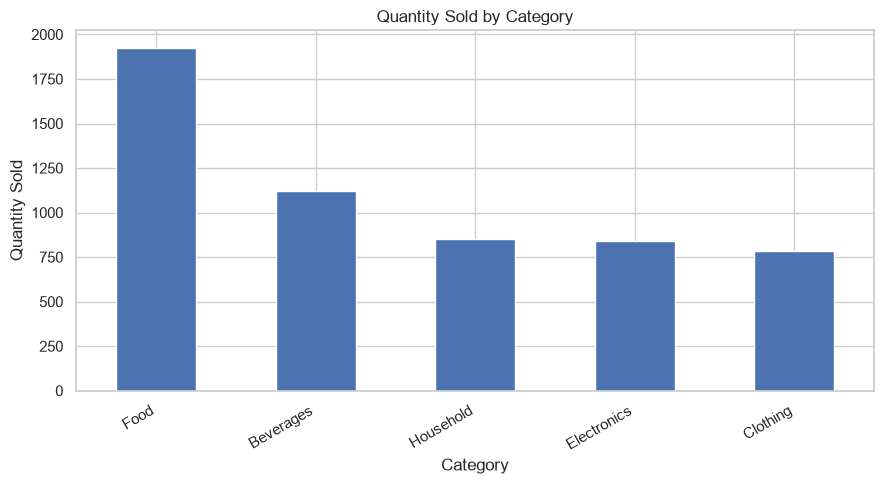

Highest quantity category: Food


In [7]:
quantity_by_category = df.groupby("Category")["Quantity"].sum().sort_values(ascending=False)
display(quantity_by_category.to_frame("Quantity Sold"))

plt.figure(figsize=(9,5))
quantity_by_category.plot(kind="bar")
plt.title("Quantity Sold by Category")
plt.xlabel("Category")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_PATH/"quantity_by_category.png", dpi=160)
plt.show()

print("Highest quantity category:", quantity_by_category.idxmax())

## 7. Payment Method Analysis

,Number of Transactions
Payment,
Cash,444
Credit Card,330
Digital Payment,226


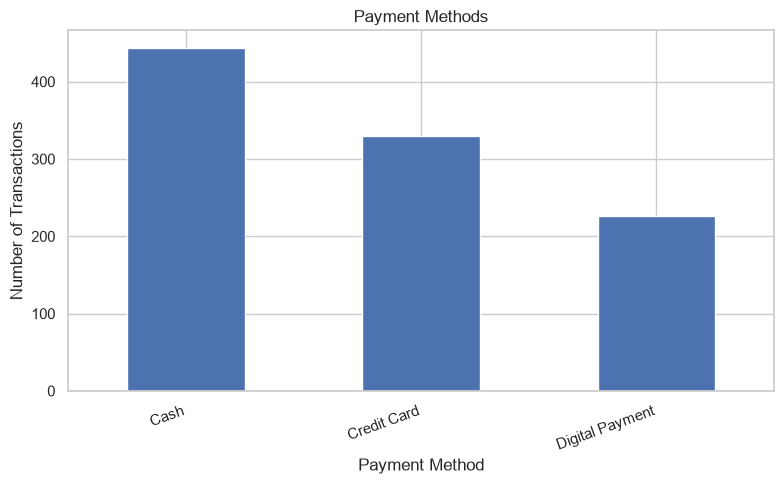

In [8]:
payment_count = df["Payment"].value_counts()
display(payment_count.to_frame("Number of Transactions"))

plt.figure(figsize=(8,5))
payment_count.plot(kind="bar")
plt.title("Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_PATH/"payment_methods.png", dpi=160)
plt.show()

## 8. Customer Type Analysis

,Total Sales
Customer Type,
Member,50636.42
Normal,31265.86


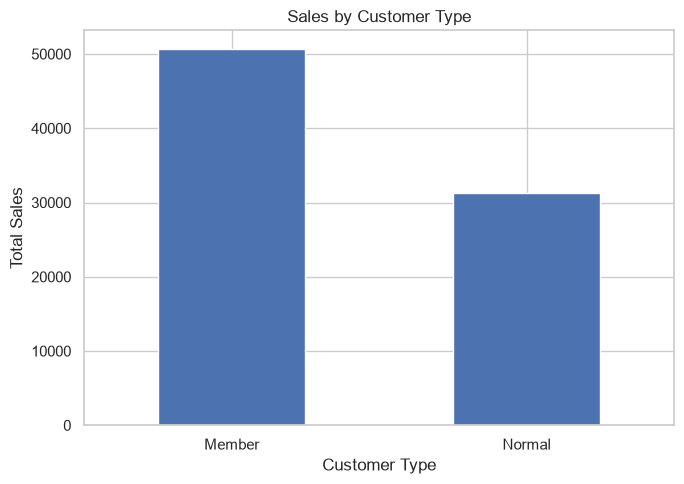

In [9]:
customer_sales = df.groupby("Customer Type")["Total"].sum().sort_values(ascending=False)
display(customer_sales.to_frame("Total Sales"))

plt.figure(figsize=(7,5))
customer_sales.plot(kind="bar")
plt.title("Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_PATH/"sales_by_customer_type.png", dpi=160)
plt.show()

## 9. Daily Sales Analysis

,Daily Sales
Date,
2023-01-01,2367.52
2023-01-02,3347.55
2023-01-03,3143.76
2023-01-04,4535.79
2023-01-05,2201.65
2023-01-06,2635.39
2023-01-07,2758.15
2023-01-08,2997.86
2023-01-09,2385.01


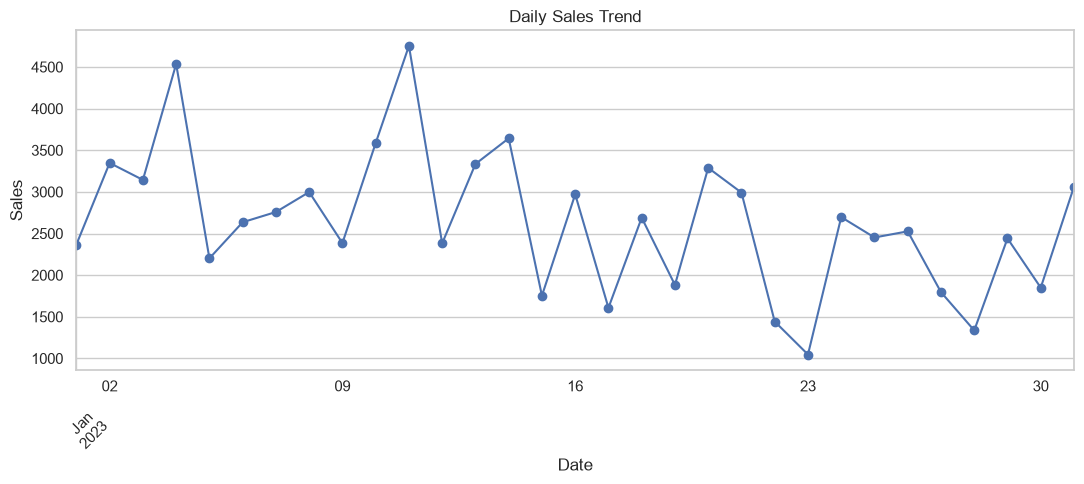

In [10]:
daily_sales = df.groupby("Date")["Total"].sum().sort_index()
display(daily_sales.head(10).to_frame("Daily Sales"))

plt.figure(figsize=(11,5))
daily_sales.plot(kind="line", marker="o")
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_PATH/"daily_sales_trend.png", dpi=160)
plt.show()

## 10. Highest and Lowest Sales Day

In [11]:
best_day = daily_sales.idxmax()
best_day_sales = daily_sales.max()
lowest_day = daily_sales.idxmin()
lowest_day_sales = daily_sales.min()
average_daily_sales = daily_sales.mean()

print(f"Highest Sales Day: {best_day} — ${best_day_sales:,.2f}")
print(f"Lowest Sales Day: {lowest_day} — ${lowest_day_sales:,.2f}")
print(f"Average Daily Sales: ${average_daily_sales:,.2f}")

Highest Sales Day: 2023-01-11 00:00:00 — $4,753.16
Lowest Sales Day: 2023-01-23 00:00:00 — $1,046.62
Average Daily Sales: $2,642.01


## 11. Additional Pattern Checks

In [12]:
top_products = df.groupby("Product")["Total"].sum().sort_values(ascending=False).head(5)
print("Top 5 products by sales:")
display(top_products.to_frame("Total Sales"))

print("Sales by customer type and payment method:")
display(pd.pivot_table(df, values="Total", index="Customer Type", columns="Payment", aggfunc="sum", fill_value=0).round(2))

Top 5 products by sales:


,Total Sales
Product,
Mouse,10012.07
USB Cable,7835.17
Charger,6470.39
Jeans,6343.23
Headphones,5719.01


Sales by customer type and payment method:


Payment,Cash,Credit Card,Digital Payment
Customer Type,,,
Member,26655.91,12879.42,11101.09
Normal,14985.33,11246.48,5034.05


## 12. Business Insights

In [13]:
top_category = category_sales.idxmax()
bottom_category = category_sales.idxmin()
top_payment = payment_count.idxmax()
top_customer = customer_sales.idxmax()
top_product = top_products.idxmax()

insights = [
    f"1. {top_category} generates the highest total sales among the categories.",
    f"2. {bottom_category} has the lowest total sales, so it may need promotion or assortment review.",
    f"3. {top_payment} is the most frequently used payment method.",
    f"4. {top_customer} customers contribute the highest sales value.",
    f"5. {top_product} is the top product by total sales.",
    f"6. Sales peak on {best_day} and are lowest on {lowest_day}.",
    "7. Category quantity and revenue should be compared together because selling more units does not always mean higher revenue."
]
for item in insights:
    print(item)

1. Electronics generates the highest total sales among the categories.
2. Beverages has the lowest total sales, so it may need promotion or assortment review.
3. Cash is the most frequently used payment method.
4. Member customers contribute the highest sales value.
5. Mouse is the top product by total sales.
6. Sales peak on 2023-01-11 00:00:00 and are lowest on 2023-01-23 00:00:00.
7. Category quantity and revenue should be compared together because selling more units does not always mean higher revenue.


## 13. Final Verification Checklist

In [14]:
checks = {
    "Dataset loaded": len(df) > 0,
    "Missing values checked": df.isnull().sum().sum() == 0,
    "Duplicates checked": df.duplicated().sum() == 0,
    "Date converted": pd.api.types.is_datetime64_any_dtype(df["Date"]),
    "Sales statistics calculated": total_sales > 0,
    "Category analysis completed": len(category_sales) > 0,
    "Quantity analysis completed": len(quantity_by_category) > 0,
    "Payment analysis completed": len(payment_count) > 0,
    "Customer analysis completed": len(customer_sales) > 0,
    "Daily sales analysis completed": len(daily_sales) > 0
}
display(pd.Series(checks, name="Completed"))
print("\nProject checklist complete.")

Dataset loaded                    True
Missing values checked            True
Duplicates checked                True
Date converted                    True
Sales statistics calculated       True
Category analysis completed       True
Quantity analysis completed       True
Payment analysis completed        True
Customer analysis completed       True
Daily sales analysis completed    True
Name: Completed, dtype: bool


Project checklist complete.
